# Hyperparameter tuning with Optuna

## 1. Setup and data
We load the dataframe without one-hot columns (the one-hot encoding now lives inside the Pipeline, so it is fitted only on each training fold) and start a timer to report the total execution time.

In [1]:
# Import the libraries
import sys
import time
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Make the src package importable from the notebooks folder and import the recursive forecast
sys.path.append(str(Path("..").resolve()))
from src.forecasting import recursive_forecast

# Start the timer for the total execution time
inicio = time.perf_counter()

# Load the dataframe without one-hot columns
df = pd.read_csv(Path("../data/processed/df_sin_onehot.csv"), parse_dates=["fecha"])
print(df.shape)

(2880, 37)


## 2. Pipeline and helper functions
Same column groups and same Pipeline as in `modelado_pipeline.ipynb`: one-hot encoding of the 3 categorical columns inside a `ColumnTransformer` and a `HistGradientBoostingRegressor`. `construir_pipeline` receives the hyperparameters so that every trial builds a fresh, unfitted Pipeline, and `metricas` is the same function used in the training notebook.

In [2]:
# Define the target, the categorical columns and the numeric/binary columns (same groups as modelado_pipeline.ipynb)
target = "unidades_vendidas"
cols_cat = ["nombre", "categoria", "subcategoria"]
cols_num = [col for col in df.columns if col not in cols_cat + ["fecha", "ingresos", "producto_id", target]]
predictoras = cols_cat + cols_num

# Hyperparameters of the current conservative model (the baseline to beat)
params_conservador = dict(
    learning_rate=0.03, max_iter=500, max_depth=5, max_leaf_nodes=15,
    min_samples_leaf=40, l2_regularization=1.0,
)

def construir_pipeline(params):
    """Build an unfitted Pipeline (one-hot + HistGradientBoostingRegressor) with the given hyperparameters."""
    preprocesado = ColumnTransformer(
        transformers=[("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cols_cat)],
        remainder="passthrough",
    )
    preprocesado.set_output(transform="pandas")
    modelo = HistGradientBoostingRegressor(early_stopping=False, random_state=42, **params)
    return Pipeline([("preprocesado", preprocesado), ("modelo", modelo)])

def preparar(sub):
    """Return the input of the pipeline plus fecha and producto_id, with numeric columns as float."""
    entrada = sub[["fecha", "producto_id"] + predictoras].copy()
    entrada[cols_num] = entrada[cols_num].astype(float)
    return entrada

def metricas(y_real, y_pred):
    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "MAPE (%)": np.mean(np.abs((y_real - y_pred) / y_real)) * 100,
        "WMAPE (%)": np.abs(y_real - y_pred).sum() / np.abs(y_real).sum() * 100,
        "R2": r2_score(y_real, y_pred),
    }

def evaluar_recursivo(pipe, sub):
    """Metrics of the recursive forecast on a validation year (real lags only on its first day)."""
    rec = recursive_forecast(pipe, preparar(sub))
    y_real = sub.loc[rec.index, target]
    return metricas(y_real, rec["unidades_predichas"])

## 3. Expanding-window validation inside 2021-2023
We never touch 2024 while tuning. Fold 1 trains on 2021 and validates on 2022; fold 2 trains on 2021-2022 and validates on 2023, so the training set always precedes the validation year, like in a real forecast. The objective is the mean recursive WMAPE of both folds, because the November 2025 forecast is recursive: tuning for one-step accuracy could pick a model that is good with real lags but unstable when it feeds on its own predictions.

In [3]:
# Define the expanding-window folds: (train years, validation year)
folds = [([2021], 2022), ([2021, 2022], 2023)]

def wmape_recursivo_cv(params):
    """Mean recursive WMAPE (%) over the folds for a set of hyperparameters."""
    valores = []
    for anios_train, anio_val in folds:
        train = df[df["año"].isin(anios_train)]
        val = df[df["año"] == anio_val]
        pipe = construir_pipeline(params).fit(preparar(train)[predictoras], train[target])
        valores.append(evaluar_recursivo(pipe, val)["WMAPE (%)"])
    return float(np.mean(valores)), valores

# Baseline: the conservative hyperparameters on the same folds
base_cv, base_folds = wmape_recursivo_cv(params_conservador)
print("Conservative model, recursive WMAPE by fold:", np.round(base_folds, 2), "| mean:", round(base_cv, 3))

Conservative model, recursive WMAPE by fold: [26.36 23.91] | mean: 25.132


## 4. Optuna search
TPE sampler with a fixed seed (42) and 60 trials, so the search is reproducible. The ranges go from very conservative to flexible models; `early_stopping=False` and `random_state=42` stay fixed as in the current model. `max_features` is available in this scikit-learn version (it samples a fraction of the features at each split, a regularization that can help with correlated lags).

In [4]:
# Silence the per-trial logs of Optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = dict(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        max_iter=trial.suggest_int("max_iter", 200, 1000),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        max_leaf_nodes=trial.suggest_int("max_leaf_nodes", 8, 63),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 10, 100),
        l2_regularization=trial.suggest_float("l2_regularization", 0.0, 10.0),
        max_features=trial.suggest_float("max_features", 0.5, 1.0),
    )
    media, por_fold = wmape_recursivo_cv(params)
    trial.set_user_attr("wmape_fold1", por_fold[0])
    trial.set_user_attr("wmape_fold2", por_fold[1])
    return media

# Run the study: minimize the mean recursive WMAPE
estudio = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
estudio.optimize(objective, n_trials=60)

# Keep all the trials in a dataframe
pruebas_df = estudio.trials_dataframe()
print("Best mean recursive WMAPE:", round(estudio.best_value, 3), "| conservative baseline:", round(base_cv, 3))

Best mean recursive WMAPE: 21.986 | conservative baseline: 25.132


### Best trials, optimization history and parameter importance
The table shows the 10 best trials. The history shows whether the search was still improving at the end, and the importance estimate from Optuna shows which hyperparameters actually moved the objective; with only 60 trials it is indicative, not exact.

In [5]:
# Show the 10 best trials
cols_mostrar = ["number", "value", "user_attrs_wmape_fold1", "user_attrs_wmape_fold2"] + [c for c in pruebas_df.columns if c.startswith("params_")]
pruebas_df.sort_values("value")[cols_mostrar].head(10).round(4).reset_index(drop=True)

,number,value,user_attrs_wmape_fold1,user_attrs_wmape_fold2,params_l2_regularization,params_learning_rate,params_max_depth,params_max_features,params_max_iter,params_max_leaf_nodes,params_min_samples_leaf
0,22,21.9856,22.5443,21.4269,4.4861,0.1553,7,0.5842,725,13,83
1,15,22.2435,23.0523,21.4347,4.8411,0.1821,6,0.5574,978,22,78
2,26,22.8075,23.6275,21.9875,6.0188,0.1696,6,0.6685,780,17,77
3,47,22.8212,25.1443,20.4982,7.2830,0.1764,6,0.5169,907,24,68
4,50,22.9123,23.4809,22.3437,4.0017,0.1485,6,0.5040,842,14,79
5,27,22.9319,24.9207,20.9431,6.7021,0.1311,6,0.5940,927,16,68
6,57,23.0001,23.7802,22.2200,5.9058,0.1558,6,0.6359,813,22,79
7,49,23.2111,24.7871,21.6350,5.0123,0.1346,5,0.5453,949,16,79
8,51,23.2525,25.1780,21.3270,7.4985,0.1928,7,0.5156,813,24,67
9,35,23.3118,22.9914,23.6322,6.2203,0.1524,6,0.5227,894,20,67


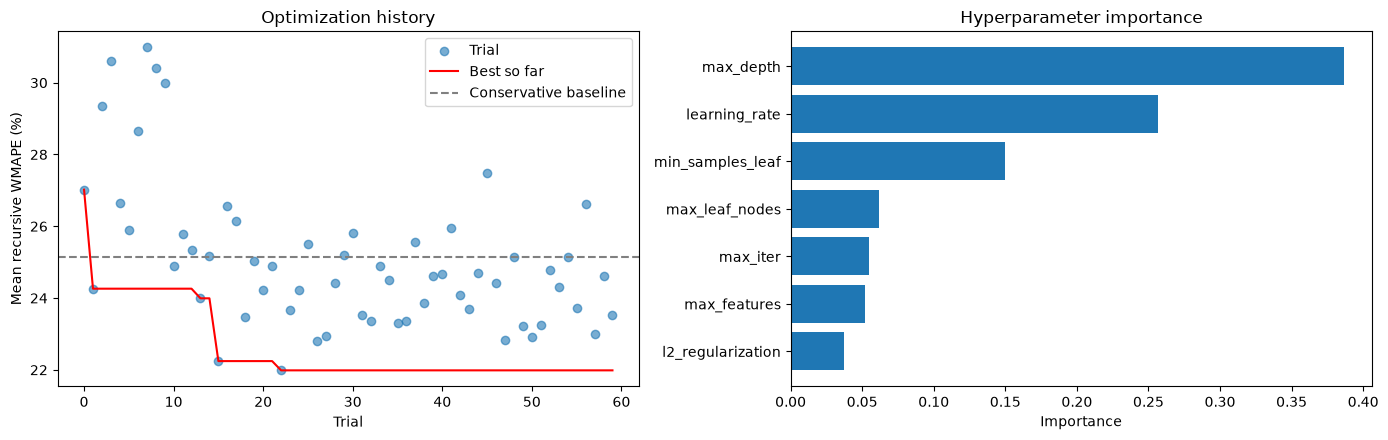

In [6]:
# Plot the optimization history (value of each trial and best value so far) and the parameter importance
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(pruebas_df["number"], pruebas_df["value"], alpha=0.6, label="Trial")
axes[0].plot(pruebas_df["number"], pruebas_df["value"].cummin(), color="red", label="Best so far")
axes[0].axhline(base_cv, color="gray", linestyle="--", label="Conservative baseline")
axes[0].set_title("Optimization history")
axes[0].set_xlabel("Trial")
axes[0].set_ylabel("Mean recursive WMAPE (%)")
axes[0].legend()

importancias = pd.Series(optuna.importance.get_param_importances(estudio)).sort_values()
axes[1].barh(importancias.index, importancias.values)
axes[1].set_title("Hyperparameter importance")
axes[1].set_xlabel("Importance")
plt.tight_layout()
plt.show()

## 5. Evaluation on 2024: conservative vs tuned
Both Pipelines are trained with 2021-2023 only and evaluated on November 2024 exactly as in `modelado_pipeline.ipynb`: one-step (real lags) and recursive (real lags only on day 1). Train metrics are one-step on 2021-2023. The train/validation gap is defined as the one-step WMAPE on 2024 minus the one-step WMAPE on train (a recursive forecast on train would chain three separate Novembers, which makes no sense).

In [7]:
# Best hyperparameters found by Optuna
mejores_params = estudio.best_params
print(mejores_params)

# Train both pipelines with 2021-2023 and prepare the 2024 data
train_df = df[df["año"] <= 2023]
val_df = df[df["año"] == 2024]
X_tr, X_va = preparar(train_df), preparar(val_df)
modelos = {
    "Conservative": construir_pipeline(params_conservador).fit(X_tr[predictoras], train_df[target]),
    "Tuned": construir_pipeline(mejores_params).fit(X_tr[predictoras], train_df[target]),
}

# Compute one-step and recursive metrics on 2024 and one-step metrics on train
filas = {}
for nombre, pipe in modelos.items():
    paso = metricas(val_df[target], pipe.predict(X_va[predictoras]))
    rec = evaluar_recursivo(pipe, val_df)
    tr = metricas(train_df[target], pipe.predict(X_tr[predictoras]))
    filas[nombre] = {
        "MAE one-step": paso["MAE"], "RMSE one-step": paso["RMSE"], "WMAPE one-step (%)": paso["WMAPE (%)"], "R2 one-step": paso["R2"],
        "MAE recursive": rec["MAE"], "RMSE recursive": rec["RMSE"], "WMAPE recursive (%)": rec["WMAPE (%)"], "R2 recursive": rec["R2"],
        "MAE train": tr["MAE"], "WMAPE train (%)": tr["WMAPE (%)"], "R2 train": tr["R2"],
        "Gap WMAPE val-train (pp)": paso["WMAPE (%)"] - tr["WMAPE (%)"],
    }
comparacion = pd.DataFrame(filas).round(3)
comparacion

{'learning_rate': 0.1553220591719787, 'max_iter': 725, 'max_depth': 7, 'max_leaf_nodes': 13, 'min_samples_leaf': 83, 'l2_regularization': 4.486143484521325, 'max_features': 0.5842319265933947}


,Conservative,Tuned
MAE one-step,1.082,0.969
RMSE one-step,2.414,1.789
WMAPE one-step (%),20.421,18.302
R2 one-step,0.870,0.929
MAE recursive,1.419,1.198
RMSE recursive,3.121,2.551
WMAPE recursive (%),26.778,22.616
R2 recursive,0.783,0.855
MAE train,0.721,0.469
WMAPE train (%),13.745,8.951


### Black Friday 2024
Black Friday (2024-11-29) is the peak day, so we compare the real units with both models' forecasts, one-step and recursive.

In [8]:
# Compare real units and forecasts on Black Friday 2024 for each model
bf_fecha = val_df.loc[val_df["es_black_friday"] == 1, "fecha"].iloc[0]
filas_bf = {}
for nombre, pipe in modelos.items():
    rec = recursive_forecast(pipe, preparar(val_df))
    bf_rec = rec[rec["fecha"] == bf_fecha]
    bf_real = val_df.loc[bf_rec.index, target]
    bf_paso = pipe.predict(X_va.loc[bf_rec.index, predictoras])
    filas_bf[nombre] = {
        "Real units": bf_real.sum(),
        "One-step units": bf_paso.sum(),
        "Recursive units": bf_rec["unidades_predichas"].sum(),
        "MAE one-step": np.abs(bf_real - bf_paso).mean(),
        "MAE recursive": np.abs(bf_real - bf_rec["unidades_predichas"]).mean(),
    }
print("Black Friday:", bf_fecha.date())
pd.DataFrame(filas_bf).T.round(2)

Black Friday: 2024-11-29


,Real units,One-step units,Recursive units,MAE one-step,MAE recursive
Conservative,450.0,360.88,330.15,3.96,5.15
Tuned,450.0,370.52,361.52,3.45,3.78


## 6. Decision and saving
Criterion fixed before looking at the results: the tuned model is adopted only if it improves the recursive WMAPE on 2024 by at least 1 percentage point **and** the train/validation gap does not increase. Note: 2024 was already used to choose the original conservative hyperparameters, so this comparison is not a fully untouched test set; the tuned model was selected without using 2024, while the baseline had that advantage. `config/best_params.json` is always saved (it is versioned); the tuned pipeline is trained on all 2,880 rows only if it is adopted.

In [9]:
# Apply the decision criterion
mejora_wmape = comparacion.loc["WMAPE recursive (%)", "Conservative"] - comparacion.loc["WMAPE recursive (%)", "Tuned"]
gap_conservador = comparacion.loc["Gap WMAPE val-train (pp)", "Conservative"]
gap_ajustado = comparacion.loc["Gap WMAPE val-train (pp)", "Tuned"]
adoptar = bool(mejora_wmape >= 1.0 and gap_ajustado <= gap_conservador)
print(f"Recursive WMAPE improvement: {mejora_wmape:.3f} pp (needs >= 1.0)")
print(f"Gap val-train: conservative {gap_conservador:.3f} pp | tuned {gap_ajustado:.3f} pp (must not increase)")
print("Adopt the tuned model:", adoptar)

# Save the best hyperparameters (versioned config) with the context of the search
ruta_config = Path("../config")
ruta_config.mkdir(parents=True, exist_ok=True)
with open(ruta_config / "best_params.json", "w", encoding="utf-8") as f:
    json.dump({
        "best_params": mejores_params,
        "fixed_params": {"early_stopping": False, "random_state": 42},
        "cv_mean_recursive_wmape": estudio.best_value,
        "cv_baseline_conservative_wmape": base_cv,
        "n_trials": len(estudio.trials),
        "sampler_seed": 42,
        "adopted": adoptar,
    }, f, indent=2)

# Only if adopted: train the tuned pipeline on all the rows (2021-2024) and save it
if adoptar:
    X_full = preparar(df)
    pipeline_ajustado = construir_pipeline(mejores_params).fit(X_full[predictoras], df[target])
    ruta_modelo = Path("../models/pipeline_final_tuned.joblib")
    ruta_modelo.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(pipeline_ajustado, ruta_modelo)
    recargado = joblib.load(ruta_modelo)
    print("Saved:", ruta_modelo, "| same predictions after loading:", np.allclose(recargado.predict(X_full[predictoras]), pipeline_ajustado.predict(X_full[predictoras])))
else:
    print("Not adopted: the tuned pipeline is not saved")

# Total execution time of the notebook
print(f"Total execution time: {time.perf_counter() - inicio:.0f} s")

Recursive WMAPE improvement: 4.162 pp (needs >= 1.0)
Gap val-train: conservative 6.676 pp | tuned 9.350 pp (must not increase)
Adopt the tuned model: False
Not adopted: the tuned pipeline is not saved
Total execution time: 176 s


## Conclusion
**Decision: the current conservative model is kept. The tuned model is NOT adopted** (`config/best_params.json` has `"adopted": false` and `models/pipeline_final_tuned.joblib` was not created).

- **Criterion 1 (recursive WMAPE improves by at least 1 pp): met.** On 2024 the recursive WMAPE goes from 26.78% to 22.62% (-4.16 pp); recursive MAE from 1.419 to 1.198 and recursive R2 from 0.783 to 0.855. In cross-validation inside 2021-2023 the mean recursive WMAPE went from 25.13% to 21.99%.
- **Criterion 2 (the train/validation gap does not increase): NOT met.** The one-step WMAPE gap (validation 2024 minus train) grows from 6.68 pp to 9.35 pp, because the tuned model fits the training years much more tightly (train WMAPE 13.7% -> 9.0%) than it improves on 2024 (one-step WMAPE 20.4% -> 18.3%).
- **Black Friday 2024-11-29** (real 450 units): the tuned model forecasts 370.5 one-step and 361.5 recursive (conservative: 360.9 and 330.2); recursive MAE per product falls from 5.15 to 3.78.
- **Reading:** by the pre-defined rule the tuned model is rejected, even though it is better on every validation metric. The rule is strict about overfitting; if a larger train/validation gap is acceptable when validation itself improves this much, the criterion should be revised explicitly (and ideally confirmed on data not used for any choice), not bent after seeing the results.
- **Caveat:** 2024 had already been used to choose the original conservative hyperparameters, so this 2024 comparison is not a clean held-out test. The tuned parameters were chosen only with 2021-2023 folds, so if anything the comparison favours the conservative model, and the improvement of the tuned one is therefore not an artifact of tuning on 2024.
- **Search notes:** the best learning rate (0.155) is near the upper end of the range (0.2), and the best trials share a high `min_samples_leaf` (about 70-80), shallow leaves (13-24) and `max_features` around 0.5-0.65.